# 4 · Parity with the original R code

**What.** Run the legacy layer (`pybasinsubs.legacy`), a line-by-line port of the BasinSubs R scripts, and compare every output table with the CSVs that R wrote (`pybasinsubs/example_data/coastal_range/r_outputs`, and the intermediate tables in `Thickness/`, `Sealevel/`).

**Why.** Proves the Python port is faithful before we change anything. The generic engine (notebook 3) intentionally differs (Monte Carlo, per-unit lithology); this notebook shows by how much.

**How the R error propagation is reproduced.** R `propagate(..., second.order = FALSE)` is the first-order delta method: $\sigma_f^2 = J\Sigma J^\top$, with J the Jacobian of the expression at the means and Σ = diag(σ²). We compute J by the complex step $\partial f/\partial x_i = \mathrm{Im}\,f(x+ih e_i)/h$, which is exact to machine precision.

Known R quirks kept on purpose in the legacy layer:
1. every unit uses the lithology of the first row of `Litho_*.csv`;
2. decompaction error seeded as |T − T₀| + 2 T₀,err; errors added linearly;
3. W₀ uses `MeanPB[3]/2` in N but `MeanPB[2]/2` in S.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
IMG = os.path.join(ROOT, "image"); os.makedirs(IMG, exist_ok=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.savefig(os.path.join(IMG, name), bbox_inches="tight"); print("saved image/" + name)

In [2]:
from pybasinsubs import data_path, legacy
def cmp(a, b):   # positional comparison of the numeric columns
    a = a.select_dtypes("number").to_numpy(float); b = b.select_dtypes("number").to_numpy(float)
    assert a.shape == b.shape, (a.shape, b.shape)
    return np.nanmax(np.abs(a - b))
rd = lambda *p: pd.read_csv(data_path("coastal_range", *p))
rows = []
for reg in "NS":
    res, rates = legacy.subsidence_analysis_r(reg)
    rows += [(reg, "Subsidence results", cmp(res, rd("r_outputs", f"Subsidence results_{reg}.csv"))),
             (reg, "vertical rates", cmp(rates, rd("r_outputs", f"vertical rates_{reg}.csv")))]
    am = legacy.age_model_r(reg)
    rows += [(reg, "Age_DepthModel", cmp(am["regressions"], rd("r_outputs", f"Age_DepthModel_{reg}.csv"))),
             (reg, "Depth_AgeModel", cmp(am["plot_regressions"], rd("r_outputs", f"Depth_AgeModel_{reg}.csv"))),
             (reg, "Ages_new", cmp(am["ages_new"], rd("Thickness", f"Ages_{reg}_new.csv"))),
             (reg, "PB_Age", cmp(legacy.pb_age_r(reg), rd("Thickness", f"PB_Age_{reg}.csv"))),
             (reg, "PB_Unit", cmp(legacy.pb_unit_r(reg), rd("Thickness", f"PB_Unit_{reg}.csv"))),
             (reg, "SL_Unit", cmp(legacy.sl_unit_r(reg), rd("Sealevel", f"SL_Unit_{reg}.csv")))]
parity = pd.DataFrame(rows, columns=["region", "table", "max_abs_diff"])
parity.to_csv(os.path.join(ROOT, "image", "nb4_parity_table.csv"), index=False)
parity.style.format({"max_abs_diff": "{:.1e}"})

,region,table,max_abs_diff
0,N,Subsidence results,6.1e-12
1,N,vertical rates,1.8e-14
2,N,Age_DepthModel,4.1e-12
3,N,Depth_AgeModel,2.2e-11
4,N,Ages_new,4.0e-13
5,N,PB_Age,5.8e-15
6,N,PB_Unit,4.5e-13
7,N,SL_Unit,4.3e-14
8,S,Subsidence results,5.0e-12
9,S,vertical rates,2.1e-14


saved image/nb4_parity_bars.png


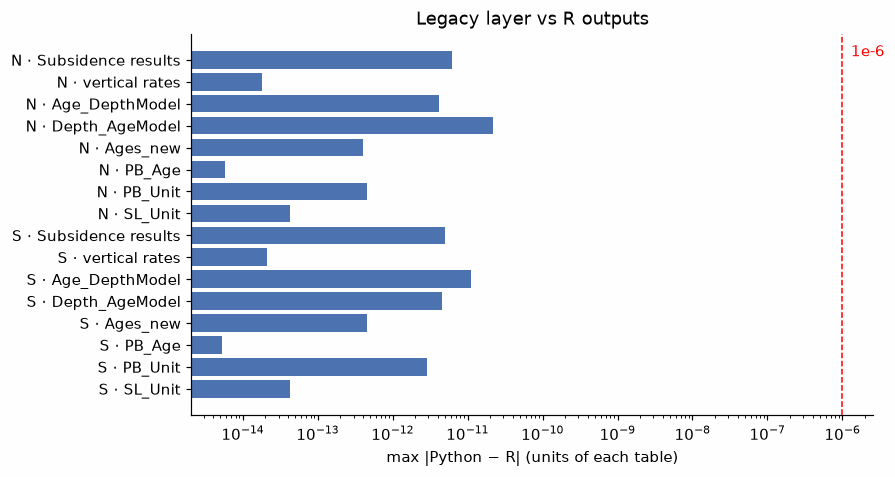

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
lab = parity.region + " · " + parity.table
ax.barh(lab, parity.max_abs_diff.clip(lower=1e-17), color="#4c72b0"); ax.set_xscale("log")
ax.axvline(1e-6, color="r", ls="--", lw=1); ax.text(1.3e-6, 0, "1e-6", color="r", va="bottom")
ax.invert_yaxis(); ax.set_xlabel("max |Python − R| (units of each table)"); ax.set_title("Legacy layer vs R outputs")
save(fig, "nb4_parity_bars.png"); plt.show()

**Reading.** Every bar is far left of the red 10⁻⁶ line: differences are floating-point rounding (≤ ~10⁻¹¹), i.e. the port is exact.

### Generic engine vs R

The generic engine is a different implementation (solid-thickness formulation, Newton solver). Run it deterministically with R's choices (first-row lithology, paper mixing) and compare; then compare the Monte Carlo spread with R's delta-method errors.

N: max |generic - R|  TotalS 1.1e-06 m, TectS 3.4e-07 m, RhoS 4.9e-08 kg/m3
   ratio R err / MC half-width: median 4.5
S: max |generic - R|  TotalS 7.6e-07 m, TectS 2.3e-07 m, RhoS 5.6e-08 kg/m3
   ratio R err / MC half-width: median 1.8


saved image/nb4_generic_vs_R_uncertainty.png


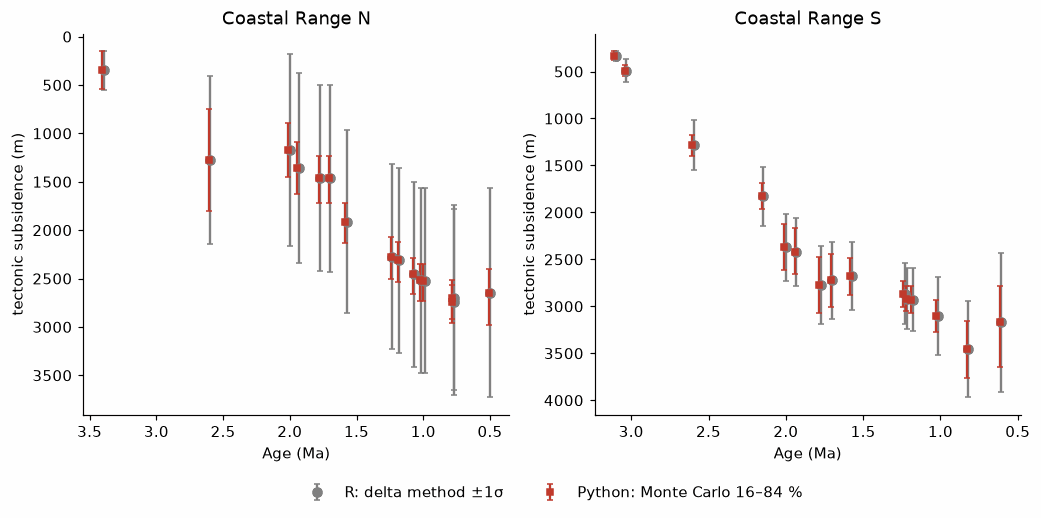

In [4]:
from pybasinsubs.column import from_basinsubs
from pybasinsubs.backstrip import backstrip
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=False)
for ax, reg in zip(axes, "NS"):
    out, _ = legacy.subsidence_analysis_r(reg)
    col = from_basinsubs(reg, litho_mode="r_first_row")
    det = backstrip(col, n=0, mc=False).summary().sort_values("age_Ma").reset_index(drop=True)
    mc = backstrip(col, n=2000, seed=0); sm = mc.summary().sort_values("age_Ma").reset_index(drop=True)
    o = out.sort_values("Age").reset_index(drop=True)
    k = min(len(o), len(det))
    print(f"{reg}: max |generic - R|  TotalS {np.max(abs(det.total_subsidence_m[:k]-o.TotalS[:k])):.1e} m, "
          f"TectS {np.max(abs(det.tectonic_subsidence_m[:k]-o.TectS[:k])):.1e} m, RhoS {np.max(abs(det.rho_s[:k]-o.RhoS[:k])):.1e} kg/m3")
    sd_mc = (sm["tectonic_subsidence_m_p84"] - sm["tectonic_subsidence_m_p16"]) / 2
    ax.errorbar(o.Age, o.TectS, yerr=o.TectS_err, fmt="o", color="grey", capsize=2, label="R: delta method ±1σ")
    ax.errorbar(sm.age_Ma + .01, sm.tectonic_subsidence_m, yerr=[sm.tectonic_subsidence_m - sm.tectonic_subsidence_m_p16, sm.tectonic_subsidence_m_p84 - sm.tectonic_subsidence_m],
                fmt="s", ms=4, color="#c0392b", capsize=2, label="Python: Monte Carlo 16–84 %")
    ax.invert_xaxis(); ax.invert_yaxis(); ax.set_xlabel("Age (Ma)"); ax.set_ylabel("tectonic subsidence (m)"); ax.set_title(f"Coastal Range {reg}")
    print(f"   ratio R err / MC half-width: median {np.median(o.TectS_err[:k] / sd_mc[:k].to_numpy()):.1f}")
axes[0].legend(loc="upper center", bbox_to_anchor=(1.1, -.15), ncol=2, frameon=False)
save(fig, "nb4_generic_vs_R_uncertainty.png"); plt.show()

**Reading.** The central values (grey circles = R, red squares = Python) coincide — the generic engine agrees with R to < 10⁻⁵ m. The error bars do not: R's delta-method errors are 2–5× larger. That is because R adds errors linearly and inflates the error of sediment density ρ_s (it propagates the full depth error into every unit). Monte Carlo propagates the same input uncertainties consistently, so its bands are narrower — and in our view more realistic. Use the legacy layer if you need to reproduce the paper's numbers exactly.